# Bump sensitivities by reverse-mode AD

Goal: the gradient of a free-surface misfit J by jax.grad, with respect to the bump parameters and to the bed in every cell, in one reverse run each.

Prerequisite: [forward-mode AD](bump_forward_ad.ipynb).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp

from zoomy_core.mesh import LSQMesh
from zoomy_core.model.boundary_conditions import Dirichlet
from zoomy_core.model.models import SME
from zoomy_core.model.models.closures import Newtonian, StressFree
from zoomy_core.numerics import NumericalSystemModel, ReconstructionSpec
from zoomy_core.systemmodel import SystemModel
from zoomy_jax.symsolver.solver import AdMode, SymbolicHyperbolicSolverJax

In [2]:
s = SME.state(level=0, dimension=2)
model = SME(
    level=0, dimension=2, closures=[Newtonian(), StressFree()],
    boundary_conditions=[
        Dirichlet("left", on=s.q_0, value=1.0),
        Dirichlet("right", on=s.h, value=1.0 - s.b),
    ],
)
nsm = NumericalSystemModel.from_system_model(
    SystemModel.from_model(model), reconstruction=ReconstructionSpec(order=1))
mesh = LSQMesh.create_1d(domain=(0.0, 10.0), n_inner_cells=100)
solver = SymbolicHyperbolicSolverJax(time_end=10.0, dt=0.02, mood=False, ad_mode=AdMode.reverse, ad_checkpoints=32)
Q0, Qaux0 = solver.setup(mesh, nsm)
x = jnp.asarray(mesh.cell_centers[0, :Q0.shape[1]])
dx = float(x[1] - x[0])

In [3]:
def bed(p):
    x0, w = p
    return 0.2 * jnp.exp(-((x - x0) / w) ** 2)


def free_surface(b):
    rows = {s.b: b, s.h: 1.0 - b, s.q_0: jnp.ones_like(b)}
    Q = jnp.stack([rows[f] for f in s])
    Q = solver.run(Q, solver.initial_aux(Q, Qaux0)).Q
    return Q[s.slot(s.b)] + Q[s.slot(s.h)]


eta = jax.jit(lambda p: free_surface(bed(p)))
p0 = jnp.array([4.73, 0.8])
e = jnp.eye(2)

In [4]:
eta_measured = eta(jnp.array([5.0, 0.8]))


def J(b):
    return 0.5 * jnp.sum((free_surface(b) - eta_measured) ** 2) * dx


dJdp = jax.grad(lambda p: J(bed(p)))(p0)
dJdb = jax.grad(J)(bed(p0))
chain = jax.vjp(bed, p0)[1](dJdb)[0]
fd = jnp.array([(J(bed(p0 + 1e-5 * e[k])) - J(bed(p0 - 1e-5 * e[k]))) / 2e-5 for k in range(2)])
print("dJ/d(x0, w) reverse      ", np.asarray(dJdp))
print("dJ/d(x0, w) central FD   ", np.asarray(fd))
print("dJ/d(x0, w) from dJ/db   ", np.asarray(chain))

dJ/d(x0, w) reverse       [-6.06056279e-04  3.10125499e-05]
dJ/d(x0, w) central FD    [-6.06056279e-04  3.10125499e-05]
dJ/d(x0, w) from dJ/db    [-6.06056279e-04  3.10125499e-05]


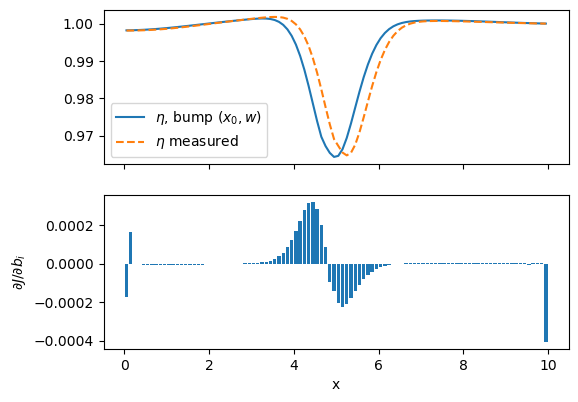

In [5]:
fig, (a, b) = plt.subplots(2, 1, figsize=(6, 4.4), sharex=True)
a.plot(x, eta(p0), label=r"$\eta$, bump $(x_0, w)$")
a.plot(x, eta_measured, "--", label=r"$\eta$ measured")
a.legend()
b.bar(x, dJdb, width=0.8 * dx)
b.set_ylabel(r"$\partial J / \partial b_i$")
b.set_xlabel("x")
plt.show()

In [6]:
scale = jnp.abs(dJdp).max()
assert jnp.abs(dJdp - fd).max() < 1e-6 * scale
assert jnp.abs(dJdp - chain).max() < 1e-12 * scale